<a href="https://colab.research.google.com/github/jimenezjos/Aplicaciones/blob/main/EjemploConDeriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solución Analítica: Movimiento Browniano con Deriva

**Problema:** Sea $X_t = \mu t + \sigma B_t$ un Movimiento Browniano con parámetros $\mu = 0.6$ y $\sigma^2 = 0.25$. Encuentre la probabilidad de que $X_t$ tome valores entre 1 y 3 al tiempo $t = 4$.

---

## 1. Definición del proceso y distribución
El proceso está definido como:

$$
X_t = \mu t + \sigma B_t
$$

Sustituimos los parámetros dados $\mu = 0.6$, $\sigma = \sqrt{0.25} = 0.5$ y evaluamos en $t = 4$:

$$
X_4 = 0.6(4) + 0.5 B_4 = 2.4 + 0.5 B_4
$$

Sabemos que el Movimiento Browniano estándar en $t=4$ tiene distribución normal:

$$
B_4 \sim N(0, 4)
$$

Al sumar una constante y multiplicar por un escalar, $X_4$ también sigue una distribución normal. Calculamos su media y varianza:

*   **Media:** $E[X_4] = 2.4 + 0.5(0) = 2.4$
*   **Varianza:** $Var(X_4) = (0.5)^2 \cdot Var(B_4) = 0.25 \cdot 4 = 1$

Por lo tanto, la distribución de $X_4$ es:

$$
X_4 \sim N(2.4, 1)
$$

---

## 2. Planteamiento de la probabilidad mediante la integral
Queremos calcular la probabilidad de que $X_4$ esté en el intervalo $(1, 3)$. Esto es el área bajo la curva de la función de densidad de probabilidad (PDF):

$$
P(1 < X_4 < 3) = \int_{1}^{3} f_{X_4}(x) \, dx
$$

Sustituyendo la función de densidad de una normal $N(2.4, 1)$:

$$
P(1 < X_4 < 3) = \int_{1}^{3} \frac{1}{\sqrt{2\pi(1)}} \exp\left(-\frac{(x - 2.4)^2}{2(1)}\right) \, dx
$$

$$
P(1 < X_4 < 3) = \int_{1}^{3} \frac{1}{\sqrt{2\pi}} e^{-\frac{(x - 2.4)^2}{2}} \, dx
$$

---

## 3. Estandarización de la integral
Para resolver esta integral, aplicamos un cambio de variable para convertirla en la Normal Estándar $Z \sim N(0,1)$. Sea:

$$
z = \frac{x - \mu}{\sigma} = \frac{x - 2.4}{1} = x - 2.4
$$

Entonces, la diferencial es $dz = dx$.

Calculamos los nuevos límites de integración:

*   Si $x = 1 \implies z = 1 - 2.4 = -1.4$
*   Si $x = 3 \implies z = 3 - 2.4 = 0.6$

Sustituyendo en la integral:

$$
P(1 < X_4 < 3) = \int_{-1.4}^{0.6} \frac{1}{\sqrt{2\pi}} e^{-\frac{z^2}{2}} \, dz
$$

---

## 4. Evaluación de la integral
La integral resultante corresponde a la función de distribución acumulada $\Phi(z)$ de la normal estándar:

$$
P(-1.4 < Z < 0.6) = \Phi(0.6) - \Phi(-1.4)
$$

Buscando los valores en la tabla de la distribución normal estándar o calculándolos:

*   $\Phi(0.6) \approx 0.7257$
*   $\Phi(-1.4) \approx 0.0808$

Restamos ambos valores:

$$
P(1 < X_4 < 3) = 0.7257 - 0.0808 = 0.6449
$$

---

## Resultado Final

$$
\boxed{ P(1 < X_4 < 3) = \int_{-1.4}^{0.6} \frac{1}{\sqrt{2\pi}} e^{-\frac{z^2}{2}} \, dz \approx 0.6449 }
$$

La probabilidad de que el proceso tome un valor entre 1 y 3 en $t=4$ es del **$64.49\%$**.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

Se simularon 10000 trayectorias.
Trayectorias que terminaron entre 1 y 3: 6407
Probabilidad estimada: 0.6407 (64.07%)


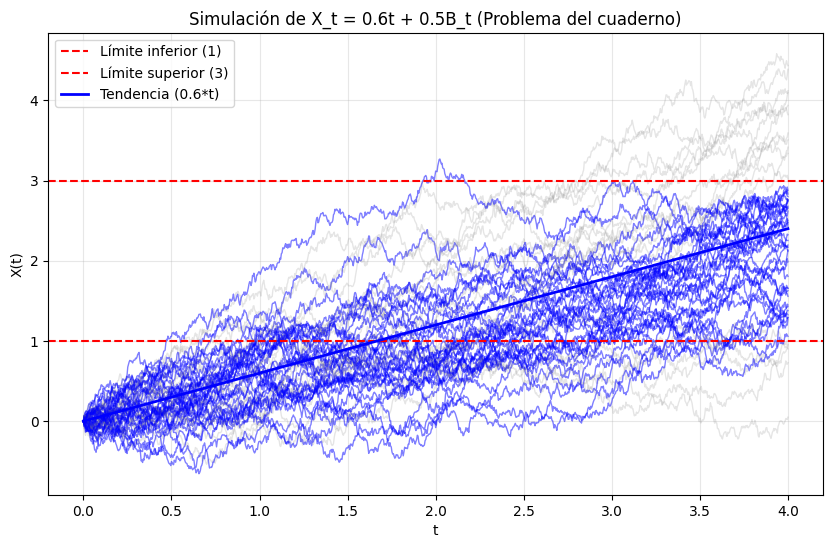

In [14]:
def simular_movimiento_browniano(T, L):
    dt = T / L
    t = np.linspace(0, T, L + 1)
    W = np.zeros(L + 1)
    W[0] = 0

    for i in range(L):
        xi = np.random.normal(0, 1)
        W[i + 1] = W[i] + np.sqrt(dt) * xi

    return t, W

def simular_mb_estandar(T, L):
    dt = T / L
    t = np.linspace(0, T, L + 1)
    W = np.zeros(L + 1)
    incrementos = np.random.normal(0, np.sqrt(dt), L)
    W[1:] = np.cumsum(incrementos)
    return t, W


def simular_mb_con_deriva(t, mu, sigma):
    dt = t[1] - t[0]
    L = len(t) - 1
    _, B_t = simular_mb_estandar(t[-1], L)
    X_t = mu * t + sigma * B_t
    return X_t

T = 4
L = 1000
mu = 0.6
sigma = 0.5
t = np.linspace(0, T, L + 1)

np.random.seed(42)
t_orig, W_orig = simular_movimiento_browniano(T, 50)

N_simulaciones = 10000
exitos = 0

np.random.seed(123)

for i in range(N_simulaciones):
    X_deriva = simular_mb_con_deriva(t, mu, sigma)
    valor_final = X_deriva[-1]

    if 1 < valor_final < 3:
        exitos += 1

prob_simulada = exitos / N_simulaciones

print(f"Se simularon {N_simulaciones} trayectorias.")
print(f"Trayectorias que terminaron entre 1 y 3: {exitos}")
print(f"Probabilidad estimada: {prob_simulada:.4f} ({prob_simulada*100:.2f}%)")
plt.figure(figsize=(10, 6))

for _ in range(50):
    X_plot = simular_mb_con_deriva(t, mu, sigma)
    if 1 < X_plot[-1] < 3:
        plt.plot(t, X_plot, color='blue', alpha=0.5, linewidth=1)
    else:
        plt.plot(t, X_plot, color='gray', alpha=0.2, linewidth=1)

plt.axhline(1, color='red', linestyle='--', label='Límite inferior (1)')
plt.axhline(3, color='red', linestyle='--', label='Límite superior (3)')
plt.plot(t, mu * t, color='blue', linewidth=2, label='Tendencia (0.6*t)')

plt.title('Simulación de X_t = 0.6t + 0.5B_t (Problema del cuaderno)')
plt.xlabel('t')
plt.ylabel('X(t)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

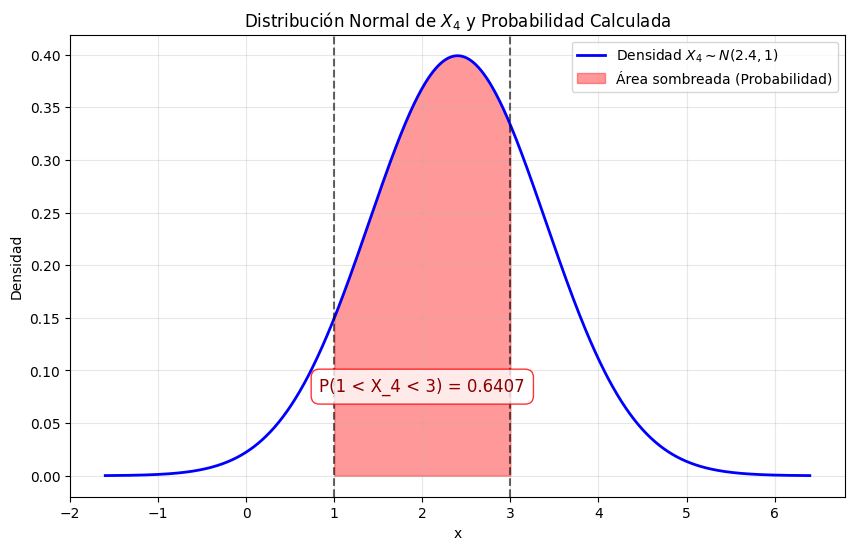

In [19]:
media = 3 - mu
desviacion_est = 1.0
probabilidad = prob_simulada

x = np.linspace(media - 4 * desviacion_est, media + 4 * desviacion_est, 1000)
y = norm.pdf(x, media, desviacion_est)

plt.figure(figsize=(10, 6))
plt.plot(x, y, color='blue', linewidth=2, label=r'Densidad $X_4 \sim N(2.4, 1)$')

x_sombra = np.linspace(1, 3, 200)
y_sombra = norm.pdf(x_sombra, media, desviacion_est)
plt.fill_between(x_sombra, y_sombra, color='red', alpha=0.4, label='Área sombreada (Probabilidad)')

plt.axvline(1, color='black', linestyle='--', alpha=0.6)
plt.axvline(3, color='black', linestyle='--', alpha=0.6)

plt.text(2.0, 0.08, f'P(1 < X_4 < 3) = {probabilidad:.4f}',
         fontsize=12, color='darkred', ha='center',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='red', boxstyle='round,pad=0.5'))

plt.title(r'Distribución Normal de $X_4$ y Probabilidad Calculada')
plt.xlabel('x')
plt.ylabel('Densidad')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.show()